In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

Kích thước gốc:        (60, 24) (Cao x Rộng)
Kích thước sau resize: (640, 640) (Cao x Rộng)
Điểm ảnh trung bình (Mean): 150.04
Độ lệch chuẩn (Std):        22.25


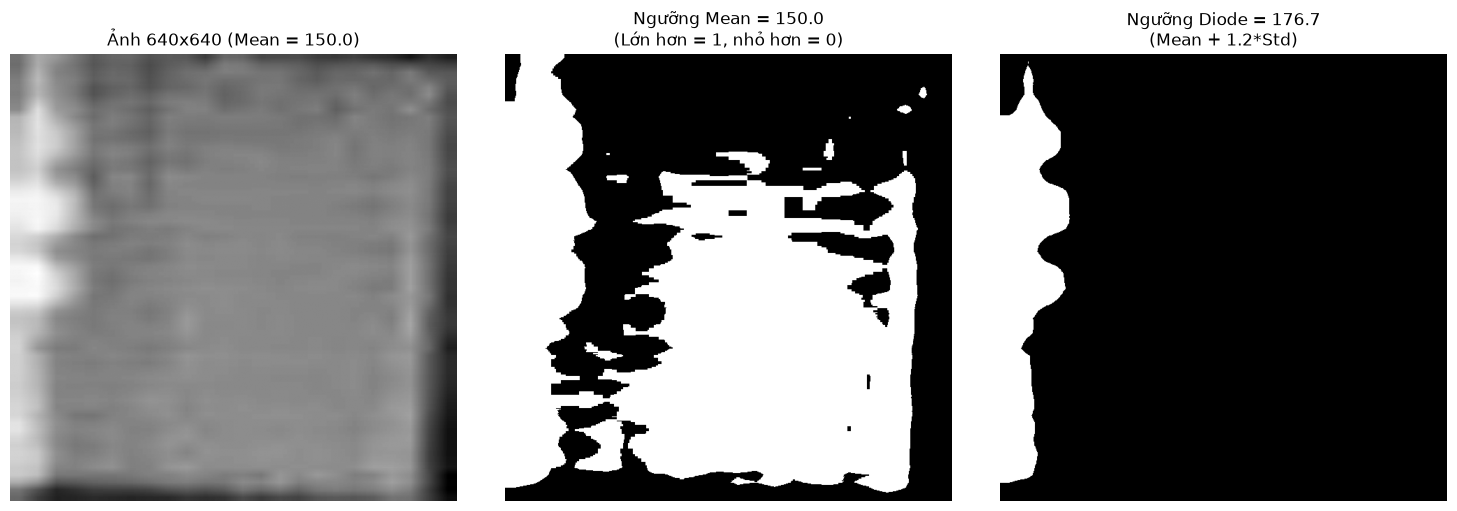

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc ảnh xám gốc
img_path = "faultme/train/images/diode_IRX_2910_jpg.rf.b064529b390dcacbe85b038aefb80991_box_14.jpg"
gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise ValueError("Kiểm tra lại đường dẫn ảnh.")

# 2. Resize về 640x640
gray_640 = cv2.resize(gray, (640, 640), interpolation=cv2.INTER_LINEAR)

# 3. Tính điểm ảnh trung bình trên ảnh 640x640
mean_val = gray_640.mean()
std_val = gray_640.std()

print(f"Kích thước gốc:        {gray.shape} (Cao x Rộng)")
print(f"Kích thước sau resize: {gray_640.shape} (Cao x Rộng)")
print(f"Điểm ảnh trung bình (Mean): {mean_val:.2f}")
print(f"Độ lệch chuẩn (Std):        {std_val:.2f}")

# 4. So sánh từng pixel với ngưỡng trung bình: > mean thì = 1, <= mean thì = 0
binary_mean = (gray_640 > mean_val).astype(np.uint8)

# (Khuyên dùng) Ngưỡng lọc sạch diode: Mean + 1.2 * Std (~176.7)
thresh_diode = mean_val + 1.2 * std_val
binary_diode = (gray_640 > thresh_diode).astype(np.uint8)

# 5. Hiển thị so sánh
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Ảnh 640x640
axes[0].imshow(gray_640, cmap="gray")
axes[0].set_title(f"Ảnh 640x640 (Mean = {mean_val:.1f})")
axes[0].axis("off")

# Nhị phân theo ngưỡng trung bình
axes[1].imshow(binary_mean, cmap="gray")
axes[1].set_title(f"Ngưỡng Mean = {mean_val:.1f}\n(Lớn hơn = 1, nhỏ hơn = 0)")
axes[1].axis("off")

# Nhị phân tối ưu lọc diode
axes[2].imshow(binary_diode, cmap="gray")
axes[2].set_title(f"Ngưỡng Diode = {thresh_diode:.1f}\n(Mean + 1.2*Std)")
axes[2].axis("off")

plt.tight_layout()
plt.show()


Loại     | Tên file                  | Gốc (HxW)    | Mean   | Std    | Ngưỡng  | Pixel lỗi 
-------------------------------------------------------------------------------------
DIODE    | diode_1.jpg               | 160x380      | 140.0  | 23.1   | 167.8   | 27,247    
DIODE    | diode_108.jpg             | 620x300      | 142.4  | 25.8   | 173.4   | 11,346    
DIODE    | diode_121.jpg             | 640x280      | 156.5  | 21.9   | 182.8   | 26,695    
DIODE    | diode_144.jpg             | 680x260      | 146.5  | 18.3   | 168.5   | 20,614    
HOTSPOT  | hotspot2_hotspot_1.jpg    | 160x380      | 154.5  | 19.5   | 177.9   | 15,151    
HOTSPOT  | hotspot2_hotspot_112.jp   | 120x380      | 154.0  | 14.4   | 171.3   | 23,279    
HOTSPOT  | hotspot2_hotspot_126.jp   | 160x380      | 143.5  | 18.3   | 165.5   | 19,870    
HOTSPOT  | hotspot2_hotspot_14.jpg   | 180x360      | 135.4  | 19.0   | 158.2   | 18,462    


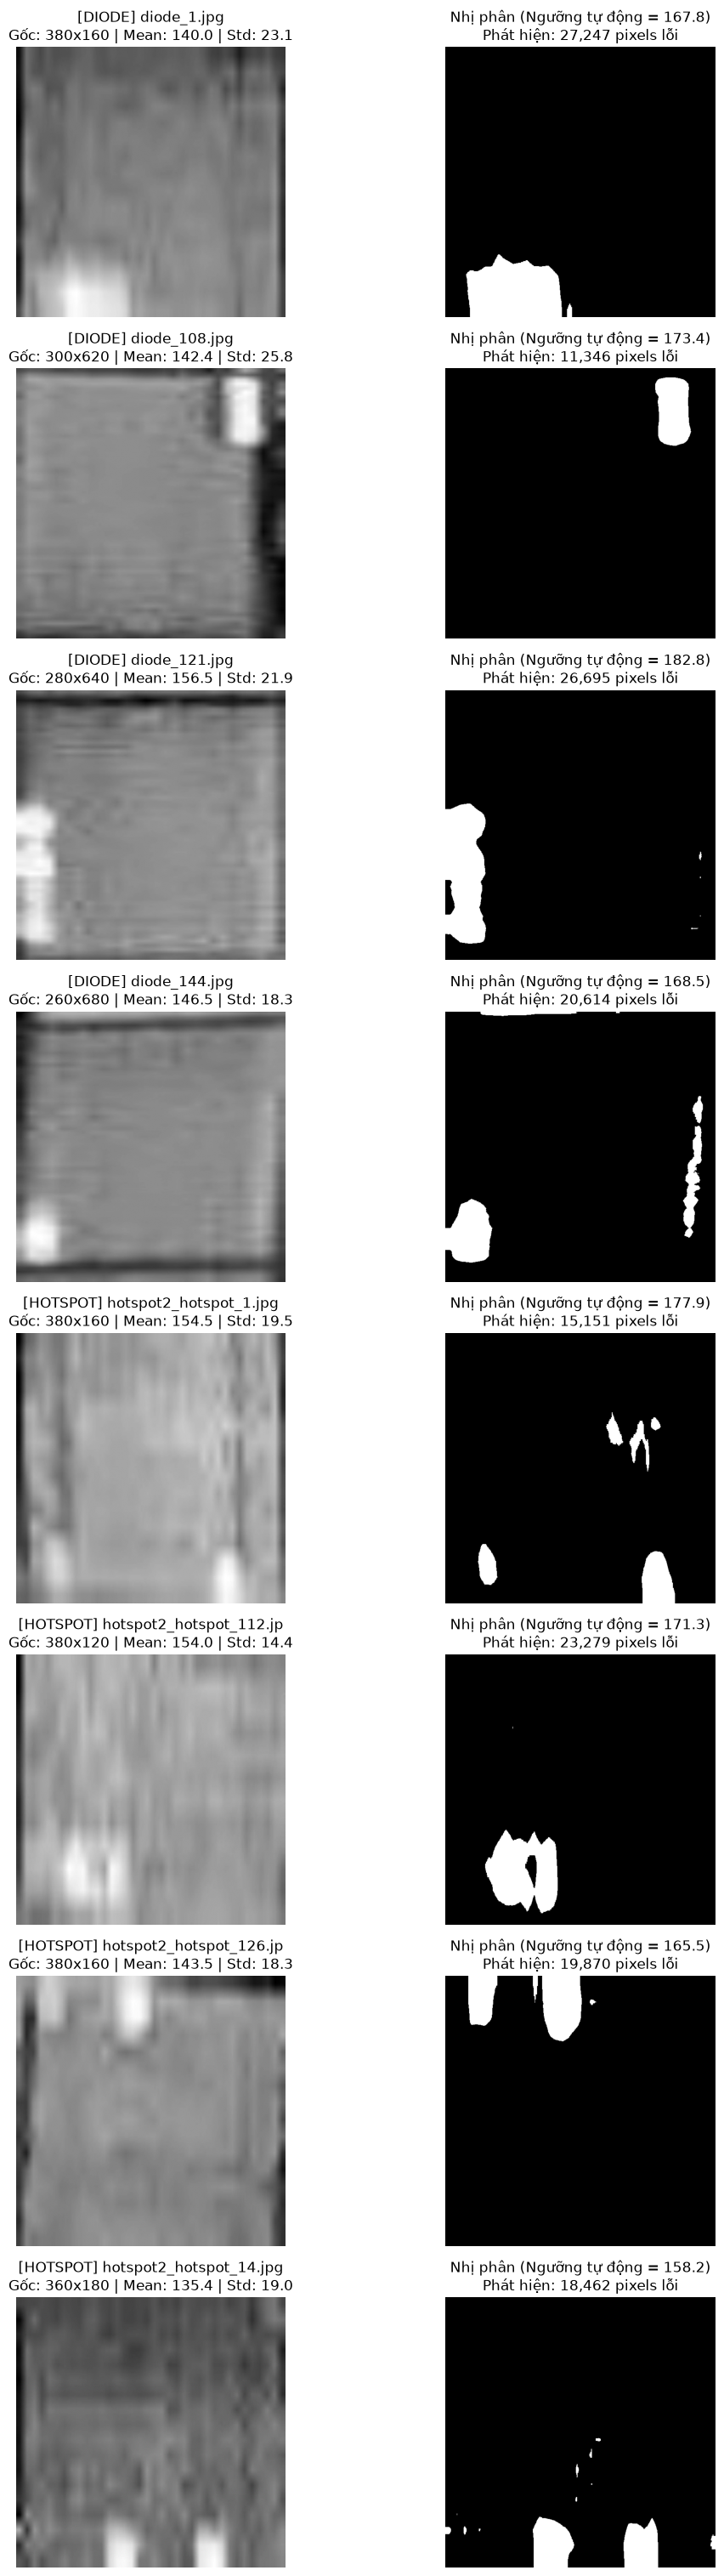

In [3]:
import glob
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Lấy danh sách ảnh Diode và Hotspot trong thư mục faultme/train/images
diode_files = sorted(glob.glob("faultme/train/images/*diode*.jpg"))
hotspot_files = sorted(glob.glob("faultme/train/images/*hotspot*.jpg"))

# Chọn 4 ảnh Diode và 4 ảnh Hotspot tiêu biểu
selected_images = [
    ("DIODE", diode_files[0]),
    ("DIODE", diode_files[10]),
    ("DIODE", diode_files[25]),
    ("DIODE", diode_files[50]),
    ("HOTSPOT", hotspot_files[0]),
    ("HOTSPOT", hotspot_files[15]),
    ("HOTSPOT", hotspot_files[30]),
    ("HOTSPOT", hotspot_files[45]),
]

# 2. Tạo khung vẽ 8 dòng x 2 cột
fig, axes = plt.subplots(len(selected_images), 2, figsize=(12, 3.8 * len(selected_images)))

print(f"{'Loại':<8} | {'Tên file':<25} | {'Gốc (HxW)':<12} | {'Mean':<6} | {'Std':<6} | {'Ngưỡng':<7} | {'Pixel lỗi':<10}")
print("-" * 85)

for i, (fault_type, img_path) in enumerate(selected_images):
    # Đọc ảnh xám
    gray_orig = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if gray_orig is None:
        continue
    h_orig, w_orig = gray_orig.shape[:2]
    
    # Resize về 640x640
    gray_640 = cv2.resize(gray_orig, (640, 640), interpolation=cv2.INTER_LINEAR)
    
    # Tự động tính ngưỡng thích nghi cho từng ảnh
    mean_val = gray_640.mean()
    std_val = gray_640.std()
    threshold = mean_val + 1.2 * std_val
    
    # Nhị phân: > ngưỡng = 1, <= ngưỡng = 0
    mask = (gray_640 > threshold).astype(np.uint8)
    pixel_count = int(mask.sum())
    
    file_name = os.path.basename(img_path)[:23]
    print(f"{fault_type:<8} | {file_name:<25} | {f'{h_orig}x{w_orig}':<12} | {mean_val:<6.1f} | {std_val:<6.1f} | {threshold:<7.1f} | {pixel_count:<10,}")
    
    # Cột 1: Ảnh 640x640
    axes[i, 0].imshow(gray_640, cmap="gray")
    axes[i, 0].set_title(f"[{fault_type}] {file_name}\nGốc: {w_orig}x{h_orig} | Mean: {mean_val:.1f} | Std: {std_val:.1f}")
    axes[i, 0].axis("off")
    
    # Cột 2: Ảnh nhị phân tách lỗi (0 và 1)
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Nhị phân (Ngưỡng tự động = {threshold:.1f})\nPhát hiện: {pixel_count:,} pixels lỗi")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


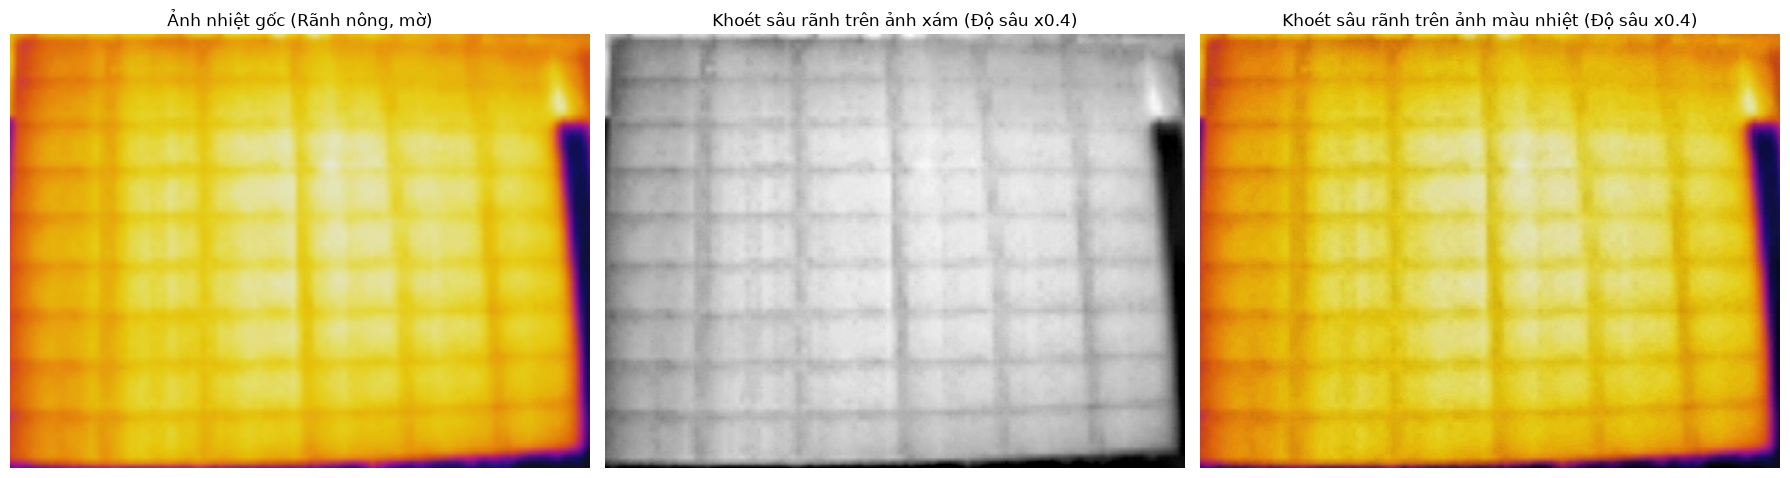

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc ảnh
img_bgr = cv2.imread("vietHuong/Screenshot 2024-05-07 215323.png")
if img_bgr is None:
    raise ValueError("Kiểm tra lại đường dẫn ảnh.")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 2. Làm nét nhẹ trước bằng Unsharp Mask để rãnh định hình rõ
gaussian = cv2.GaussianBlur(gray, (0, 0), sigmaX=3.0)
sharp = cv2.addWeighted(gray, 2.0, gaussian, -1.0, 0)

# 3. Trích xuất chính xác mạng lưới rãnh dọc & ngang bằng Black-Hat
k_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 21))  # Bắt rãnh dọc
k_h = cv2.getStructuringElement(cv2.MORPH_RECT, (21, 1))  # Bắt rãnh ngang

grooves_v = cv2.morphologyEx(sharp, cv2.MORPH_BLACKHAT, k_v)
grooves_h = cv2.morphologyEx(sharp, cv2.MORPH_BLACKHAT, k_h)
grooves = cv2.add(grooves_v, grooves_h)  # Tổng hợp toàn bộ rãnh

# 4. KHOÉT SÂU RÃNH (Hệ số khoét depth = 4.0, bạn có thể tăng giảm tùy ý)
depth = 0.4

# 4.1. Khoét sâu trên ảnh xám
carved_gray = cv2.subtract(sharp, np.clip(grooves * depth, 0, 255).astype(np.uint8))

# 4.2. Khoét sâu trên ảnh màu nhiệt gốc (dìm độ sáng kênh V trong không gian màu HSV)
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
hsv[:, :, 2] = np.clip(hsv[:, :, 2] - grooves.astype(np.float32) * depth, 0, 255)
carved_color = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

# 5. Hiển thị so sánh
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Ảnh nhiệt gốc (Rãnh nông, mờ)")
axes[0].axis("off")

axes[1].imshow(carved_gray, cmap="gray")
axes[1].set_title(f"Khoét sâu rãnh trên ảnh xám (Độ sâu x{depth})")
axes[1].axis("off")

axes[2].imshow(carved_color)
axes[2].set_title(f"Khoét sâu rãnh trên ảnh màu nhiệt (Độ sâu x{depth})")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def process_and_carve_640(img_path):
    # 1. Đọc ảnh
    bgr = cv2.imread(img_path)
    if bgr is None:
        raise ValueError(f"Không thể đọc ảnh: {img_path}")
    
    # 2. CỐ ĐỊNH KÍCH THƯỚC ĐẦU VÀO 640x640 (Chuẩn đầu vào YOLO)
    bgr_640 = cv2.resize(bgr, (640, 640), interpolation=cv2.INTER_LINEAR)
    rgb_640 = cv2.cvtColor(bgr_640, cv2.COLOR_BGR2RGB)
    gray_640 = cv2.cvtColor(bgr_640, cv2.COLOR_BGR2GRAY)
    
    # 3. Làm nét nhẹ trước để tách biên rãnh
    gaussian = cv2.GaussianBlur(gray_640, (0, 0), sigmaX=3.0)
    sharp = cv2.addWeighted(gray_640, 2.0, gaussian, -1.0, 0)
    
    # 4. Trích xuất rãnh cho chuẩn kích thước 640x640 (thước dò 25px là chuẩn nhất)
    k_len = 25
    kv = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k_len))  # Dò rãnh dọc
    kh = cv2.getStructuringElement(cv2.MORPH_RECT, (k_len, 1))  # Dò rãnh ngang
    
    grooves = cv2.add(cv2.morphologyEx(sharp, cv2.MORPH_BLACKHAT, kv),
                      cv2.morphologyEx(sharp, cv2.MORPH_BLACKHAT, kh))
    
    # 5. Tự động tính độ sâu khoét theo độ tương phản của ảnh 640x640
    std_val = gray_640.std()
    auto_depth = float(np.clip(100.0 / (std_val + 1e-5), 2.0, 5.0))
    
    # 6. Khoét sâu rãnh:
    # 6.1. Trên ảnh xám (640x640)
    carved_gray = cv2.subtract(sharp, np.clip(grooves * auto_depth, 0, 255).astype(np.uint8))
    
    # 6.2. Trên ảnh màu (640x640)
    hsv = cv2.cvtColor(bgr_640, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:, :, 2] = np.clip(hsv[:, :, 2] - grooves.astype(np.float32) * auto_depth, 0, 255)
    carved_color = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    
    return rgb_640, carved_gray, carved_color, auto_depth


# --- CHẠY THỬ VÀ HIỂN THỊ ---
img_path = "data_train_panel_fault_gray/train/images/train_0052.jpg"
orig_640, gray_640, color_640, depth = process_and_carve_640(img_path)

print(f"Kích thước ảnh gốc sau resize:  {orig_640.shape}")
print(f"Kích thước ảnh sau khoét rãnh:  {color_640.shape}")
print(f"Độ sâu khoét máy tự tính:       {depth:.2f}")

# Hiển thị 3 ảnh kết quả (đều đúng 640x640)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(orig_640)
axes[0].set_title(f"Ảnh gốc (640x640)")
axes[0].axis("off")

axes[1].imshow(gray_640, cmap="gray")
axes[1].set_title(f"Khoét rãnh xám (640x640)")
axes[1].axis("off")

axes[2].imshow(color_640)
axes[2].set_title(f"Khoét rãnh màu (640x640 | Tự tính depth={depth:.2f})")
axes[2].axis("off")

plt.tight_layout()
plt.show()


[ WARN:0@68.128] global loadsave.cpp:278 findDecoder imread_('data_train_panel_fault_gray/train/images/train_0052.jpg'): can't open/read file: check file path/integrity


ValueError: Không thể đọc ảnh: data_train_panel_fault_gray/train/images/train_0052.jpg

In [11]:
import os
import glob
import shutil

dataset_root = "solar_panel_phuocvnd"
splits = ["train", "valid", "test"]

CONTINUOUS_NUMBERING = True  
global_counter = 1

print(f"=== ĐỔI TÊN TOÀN BỘ FILE TRONG {dataset_root} SANG image_0001, image_0002... ===")

for split in splits:
    img_dir = os.path.join(dataset_root, split, "images")
    lbl_dir = os.path.join(dataset_root, split, "labels")
    
    if not os.path.exists(img_dir) or not os.path.exists(lbl_dir):
        continue
    
    img_files = sorted(glob.glob(os.path.join(img_dir, "*.*")))
    
    # Tạo thư mục tạm để chuyển an toàn
    tmp_img_dir = os.path.join(dataset_root, split, "images_tmp")
    tmp_lbl_dir = os.path.join(dataset_root, split, "labels_tmp")
    os.makedirs(tmp_img_dir, exist_ok=True)
    os.makedirs(tmp_lbl_dir, exist_ok=True)
    
    start_num = global_counter if CONTINUOUS_NUMBERING else 1
    split_counter = start_num
    
    for old_img_path in img_files:
        old_stem = os.path.splitext(os.path.basename(old_img_path))[0]
        old_ext = os.path.splitext(old_img_path)[1]
        
        # Tên mới: image_0001, image_0002...
        new_stem = f"image_{split_counter:04d}"
        new_img_path = os.path.join(tmp_img_dir, f"{new_stem}{old_ext}")
        new_lbl_path = os.path.join(tmp_lbl_dir, f"{new_stem}.txt")
        
        # 1. Sao chép ảnh màu sang tên mới
        shutil.copy2(old_img_path, new_img_path)
        
        # 2. Sao chép file label sang tên mới tương ứng
        old_lbl_path = os.path.join(lbl_dir, old_stem + ".txt")
        if os.path.exists(old_lbl_path):
            shutil.copy2(old_lbl_path, new_lbl_path)
        else:
            open(new_lbl_path, "w").close()
            
        split_counter += 1
    
    if CONTINUOUS_NUMBERING:
        global_counter = split_counter
        
    # Thay thế thư mục cũ bằng thư mục mới
    shutil.rmtree(img_dir)
    shutil.rmtree(lbl_dir)
    os.rename(tmp_img_dir, img_dir)
    os.rename(tmp_lbl_dir, lbl_dir)
    
    end_num = split_counter - 1
    print(f"[{split}]: Đã đổi thành công từ image_{start_num:04d} đến image_{end_num:04d}")

print("\n=== HOÀN TẤT ĐỔI TÊN CHO data_train_panel_fault! ===")


=== ĐỔI TÊN TOÀN BỘ FILE TRONG solar_panel_phuocvnd SANG image_0001, image_0002... ===
[train]: Đã đổi thành công từ image_0001 đến image_0420
[valid]: Đã đổi thành công từ image_0421 đến image_0452
[test]: Đã đổi thành công từ image_0453 đến image_0484

=== HOÀN TẤT ĐỔI TÊN CHO data_train_panel_fault! ===


In [10]:
from pathlib import Path
import shutil
import math
import json

# ============================================================
# 1. CẤU HÌNH
# ============================================================

# Dataset gốc chưa padding
SOURCE_ROOT = Path("data_final_renamed").resolve()

# Dataset mới sau khi nới box
OUTPUT_ROOT = Path("data_train_panel_fault_paddingbox").resolve()

# Tăng tổng chiều rộng/cao thêm 10%
PADDING_RATIO = 0.10

SPLITS = ["train", "valid", "test"]

if not SOURCE_ROOT.is_dir():
    raise FileNotFoundError(f"Không tìm thấy: {SOURCE_ROOT}")

if OUTPUT_ROOT.exists():
    raise FileExistsError(
        f"Output đã tồn tại: {OUTPUT_ROOT}\n"
        "Hãy đổi OUTPUT_ROOT để tránh ghi đè."
    )

if SOURCE_ROOT in OUTPUT_ROOT.parents:
    raise ValueError("Output không được nằm trong dataset nguồn.")

# ============================================================
# 2. KIỂM TRA VÀ CHUẨN BỊ LABEL MỚI
# ============================================================

converted_labels = {}
statistics = {}

for split in SPLITS:
    label_dir = SOURCE_ROOT / split / "labels"

    if not label_dir.is_dir():
        raise FileNotFoundError(f"Thiếu thư mục: {label_dir}")

    label_files = sorted(label_dir.glob("*.txt"))

    if not label_files:
        raise ValueError(f"Không có file label trong: {label_dir}")

    box_count = 0
    clipped_count = 0

    for label_path in label_files:
        new_lines = []

        for line_number, line in enumerate(
            label_path.read_text(encoding="utf-8-sig").splitlines(),
            start=1,
        ):
            if not line.strip():
                continue

            parts = line.split()

            if len(parts) != 5:
                raise ValueError(
                    f"{label_path}, dòng {line_number}: "
                    "label detection phải có đúng 5 cột."
                )

            try:
                class_value, xc, yc, bw, bh = map(float, parts)
            except ValueError as error:
                raise ValueError(
                    f"{label_path}, dòng {line_number}: "
                    "có giá trị không phải số."
                ) from error

            if not all(
                math.isfinite(value)
                for value in [class_value, xc, yc, bw, bh]
            ):
                raise ValueError(
                    f"{label_path}, dòng {line_number}: có NaN/vô cực."
                )

            if (
                not class_value.is_integer()
                or int(class_value) not in {0, 1, 2, 3}
            ):
                raise ValueError(
                    f"{label_path}, dòng {line_number}: "
                    "class ID phải thuộc 0–3."
                )

            if not (
                0 <= xc <= 1
                and 0 <= yc <= 1
                and 0 < bw <= 1
                and 0 < bh <= 1
            ):
                raise ValueError(
                    f"{label_path}, dòng {line_number}: "
                    "tọa độ hoặc kích thước không hợp lệ."
                )

            # Tăng tổng chiều rộng/cao thêm 10%
            expanded_w = bw * (1 + PADDING_RATIO)
            expanded_h = bh * (1 + PADDING_RATIO)

            xmin_raw = xc - expanded_w / 2
            xmax_raw = xc + expanded_w / 2
            ymin_raw = yc - expanded_h / 2
            ymax_raw = yc + expanded_h / 2

            # Cắt phần vượt mép ảnh
            xmin = max(0.0, xmin_raw)
            xmax = min(1.0, xmax_raw)
            ymin = max(0.0, ymin_raw)
            ymax = min(1.0, ymax_raw)

            if (
                xmin_raw < 0 or xmax_raw > 1
                or ymin_raw < 0 or ymax_raw > 1
            ):
                clipped_count += 1

            # Tính lại tâm sau khi giới hạn trong ảnh
            new_xc = (xmin + xmax) / 2
            new_yc = (ymin + ymax) / 2
            new_bw = xmax - xmin
            new_bh = ymax - ymin

            new_lines.append(
                f"{int(class_value)} "
                f"{new_xc:.8f} {new_yc:.8f} "
                f"{new_bw:.8f} {new_bh:.8f}"
            )

            box_count += 1

        # File label rỗng vẫn được giữ rỗng
        relative_path = label_path.relative_to(SOURCE_ROOT)

        converted_labels[relative_path] = (
            "\n".join(new_lines) + ("\n" if new_lines else "")
        )

    statistics[split] = {
        "files": len(label_files),
        "boxes": box_count,
        "clipped": clipped_count,
    }

# ============================================================
# 3. COPY DATASET, BỎ CACHE CŨ
# ============================================================

shutil.copytree(
    SOURCE_ROOT,
    OUTPUT_ROOT,
    ignore=shutil.ignore_patterns("*.cache"),
)

for relative_path, content in converted_labels.items():
    destination = OUTPUT_ROOT / relative_path
    destination.write_text(content, encoding="utf-8")

    # Kiểm tra nội dung đã ghi
    if destination.read_text(encoding="utf-8") != content:
        raise RuntimeError(f"Ghi label không thành công: {destination}")

# ============================================================
# 4. TẠO YAML TRỎ TỚI DATASET MỚI
# ============================================================

yaml_content = f"""path: {json.dumps(str(OUTPUT_ROOT), ensure_ascii=False)}

train: train/images
val: valid/images
test: test/images

channels: 1

nc: 4
names:
  0: Hotspot
  1: Normal
  2: Shadow
  3: Diode
"""

yaml_path = OUTPUT_ROOT / "data_gray.yaml"
yaml_path.write_text(yaml_content, encoding="utf-8")

# ============================================================
# 5. THỐNG KÊ
# ============================================================

for split, stats in statistics.items():
    print(
        f"✅ {split}: {stats['files']} file | "
        f"{stats['boxes']} box | "
        f"{stats['clipped']} box chạm mép ảnh"
    )

print(f"\n✅ Đã tăng chiều rộng/cao box thêm {PADDING_RATIO:.0%}")
print(f"📁 Dataset mới: {OUTPUT_ROOT}")
print(f"📄 YAML train: {yaml_path}")
print("✅ Ảnh, class ID và dataset gốc được giữ nguyên.")

✅ train: 116 file | 6741 box | 278 box chạm mép ảnh
✅ valid: 29 file | 1707 box | 78 box chạm mép ảnh
✅ test: 29 file | 1707 box | 78 box chạm mép ảnh

✅ Đã tăng chiều rộng/cao box thêm 10%
📁 Dataset mới: /Users/phuocvnd/Desktop/phuocvnd/-solar_panel/data_train_panel_fault_paddingbox
📄 YAML train: /Users/phuocvnd/Desktop/phuocvnd/-solar_panel/data_train_panel_fault_paddingbox/data_gray.yaml
✅ Ảnh, class ID và dataset gốc được giữ nguyên.
